# Calculating the price of a down-and-out-put option using fluid mechanics
Two algorithms will be compared to each other: MPDATA and upwind using `PyMPDATA`.

### Question
Do fluid mechanics allow for adequate pricing of a down-and-out-put option?

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PyMPDATA-examples')

In [2]:
import numpy as np
from matplotlib import pyplot
from open_atmos_jupyter_utils import show_plot, show_anim
from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions
from scipy.special import erf

## Solver basing on `PyMPDATA`

In [3]:
class DownAndOutPutIntegrator:
    def __init__(self, *, strike_price, barrier_price, volatility, risk_free_interest_rate, nx, options = None):
        options = options or Options(nonoscillatory=True, infinite_gauge=True)
        
        self.K = strike_price
        self.B = barrier_price
        self.r = risk_free_interest_rate
        self.sigma = volatility

        x_min = np.log(self.B / self.K)
        x_max = max(4.0 * np.log(self.K / self.B), 1.5)
        self.dx = (x_max - x_min) / nx
        self.x = x_min + (np.arange(nx) + 0.5) * self.dx
        self.S = self.K * np.exp(self.x)

        payout = np.where((self.B < self.S) & (self.S < self.K), self.K - self.S, 0.0)
        common = {
            'halo' : options.n_halo,
            'boundary_conditions' : (boundary_conditions.Constant(value=0),)
        }
        
        self.advectee = ScalarField(**common, data=payout)
        self.advector = VectorField(**common, data=(np.zeros(nx + 1),))
        self.solver = Solver(advector=self.advector, advectee=self.advectee, stepper=Stepper(n_dims=1, options=options))

    def _update_courant_numbers(self, *, dt, eps=1e-12):
        psi = self.advectee.get()
        psi_padded = np.pad(psi, 1, constant_values=0.0)
        c_adv = (0.5 * self.sigma**2 - self.r) * dt / self.dx
        lambda_sq = 0.5 * self.sigma**2 * dt / (self.dx**2)
        c_diff = -lambda_sq * np.diff(psi_padded) / (0.5 * (psi_padded[1:] + psi_padded[:-1]) + eps)
        courant = self.advector.get_component(0)
        courant[:] = c_adv + c_diff
        
        assert np.amax(np.abs(courant)) <= 1.0

    def __call__(self, *, nt, T, outfreq, eps=1e-7):
        dt = T / nt
        output = []
        for it in range(nt + 1):
            if it != 0:
                self._update_courant_numbers(dt=dt)
                self.solver.advance(n_steps=1)
            if it % outfreq == 0:
                output.append(self.advectee.get().copy() * np.exp(-self.r * it * dt))
        return output

## The analytical solution to price a down-and-out option

In [4]:
def AnalyticalDownAndOutPutSolver(S, K, B, T, r, sigma):
    norm_cdf = lambda z: 0.5 * (1.0 + erf(z / np.sqrt(2.0)))

    def vanilla_put(s, strike):
        d1 = (np.log(s / strike) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)
        return strike * np.exp(-r * T) * norm_cdf(-d2) - s * norm_cdf(-d1)

    def binary_put(s, strike):
        d2 = (np.log(s / strike) + (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        return np.exp(-r * T) * norm_cdf(-d2)

    def truncated_put(s):
        return vanilla_put(s, K) - vanilla_put(s, B) - (K - B) * binary_put(s, B)

    power = 2.0 * r / (sigma**2) - 1.0
    result = truncated_put(S) - (B / S)**power * truncated_put((B**2) / S)
    return np.where(S > B, result, 0.0)

## Example simulations

In [5]:
strike_price = 120
barrier_price = 80
volatility = 35 / 100
risk_free_interest_rate = 5 / 100
T = 0.5
nx = 100
outfreq = 5

integ_MPDATA = DownAndOutPutIntegrator(
        strike_price=strike_price, 
        barrier_price=barrier_price,
        volatility=volatility, 
        risk_free_interest_rate=risk_free_interest_rate,
        nx=nx)
integ_upwind = DownAndOutPutIntegrator(
        strike_price=strike_price, 
        barrier_price=barrier_price,
        volatility=volatility, 
        risk_free_interest_rate=risk_free_interest_rate,
        nx=nx,
        options=Options(n_iters=1))

dx = integ_MPDATA.dx
nt = int(np.ceil(volatility**2 * T / (0.5 * dx**2)))
outfreq = max(1, nt // 100)

output_MPDATA = integ_MPDATA(nt=nt, T=T, outfreq=outfreq)
output_upwind = integ_upwind(nt=nt, T=T, outfreq=outfreq)

## Visulaization

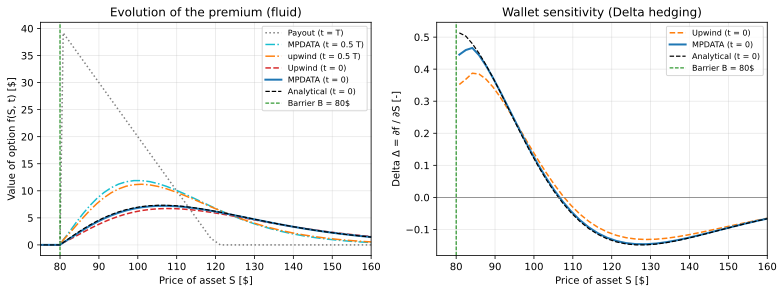

In [6]:
S = integ_MPDATA.S
S_plot = np.concatenate(([60.0, barrier_price], S))
pad_zeros = lambda arr: np.concatenate(([0.0, 0.0], arr))

analytical_price = AnalyticalDownAndOutPutSolver(S, strike_price, barrier_price, T, risk_free_interest_rate, volatility)
analytical_delta = np.gradient(analytical_price, S)
mpdata_delta = np.gradient(output_MPDATA[-1], S)
upwind_delta = np.gradient(output_upwind[-1], S)

fig, (ax_price, ax_delta) = pyplot.subplots(1, 2, figsize=(11, 4.2))

ax_price.plot(S_plot, pad_zeros(output_MPDATA[0]), linestyle=':', color='gray', label='Payout (t = T)')
ax_price.plot(S_plot, pad_zeros(output_MPDATA[len(output_MPDATA) // 2]), linestyle='-.', color='tab:cyan', label='MPDATA (t = 0.5 T)')
ax_price.plot(S_plot, pad_zeros(output_upwind[len(output_upwind) // 2]), linestyle='-.', color='tab:orange', label='upwind (t = 0.5 T)')
ax_price.plot(S_plot, pad_zeros(output_upwind[-1]), linestyle='--', color='tab:red', label='Upwind (t = 0)')
ax_price.plot(S_plot, pad_zeros(output_MPDATA[-1]), color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
ax_price.plot(S_plot, pad_zeros(analytical_price), linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')
ax_price.axvline(barrier_price, color='green', linestyle='--', linewidth=1, label=f'Barrier B = {barrier_price}$')
ax_price.set_xlim(75, 160)
ax_price.set_xlabel('Price of asset S [$]')
ax_price.set_ylabel('Value of option f(S, t) [$]')
ax_price.set_title('Evolution of the premium (fluid)')
ax_price.grid(True, alpha=0.3)
ax_price.legend(fontsize=8)

ax_delta.plot(S, upwind_delta, linestyle='--', color='tab:orange', label='Upwind (t = 0)')
ax_delta.plot(S, mpdata_delta, color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
ax_delta.plot(S, analytical_delta, linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')
ax_delta.axvline(barrier_price, color='green', linestyle='--', linewidth=1, label=f'Barrier B = {barrier_price}$')
ax_delta.axhline(0, color='gray', linewidth=0.8)
ax_delta.set_xlim(75, 160)
ax_delta.set_xlabel('Price of asset S [$]')
ax_delta.set_ylabel('Delta Δ = ∂f / ∂S [-]')
ax_delta.set_title('Wallet sensitivity (Delta hedging)')
ax_delta.grid(True, alpha=0.3)
ax_delta.legend(fontsize=8)

pyplot.tight_layout()
show_plot('down_and_out_put')


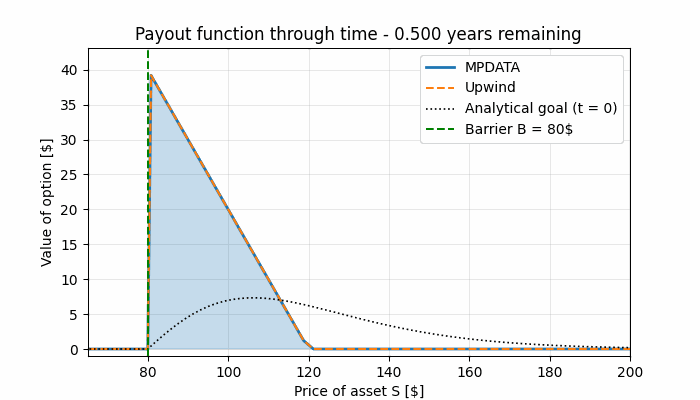

HTML(value="<a href='.\\tmp5n_mtl6i.gif' target='_blank'>.\\tmp5n_mtl6i.gif</a><br>")

In [7]:
dt_frame = T / (len(output_MPDATA) - 1)
y_max = np.max(output_MPDATA[0]) * 1.1

def plot(frame):
    fig, ax = pyplot.subplots(figsize=(7, 4))
    tau = frame * dt_frame
    t_remaining = T - tau
    ax.fill_between(S_plot, pad_zeros(output_MPDATA[frame]), color='tab:blue', alpha=0.25)
    ax.plot(S_plot, pad_zeros(output_MPDATA[frame]), color='tab:blue', linewidth=2, label='MPDATA')
    ax.plot(S_plot, pad_zeros(output_upwind[frame]), color='tab:orange', linestyle='--', linewidth=1.5, label='Upwind')
    ax.plot(S_plot, pad_zeros(analytical_price), color='black', linestyle=':', linewidth=1.2, label='Analytical goal (t = 0)')
    ax.axvline(barrier_price, color='green', linestyle='--', linewidth=1.5, label=f'Barrier B = {barrier_price}$')
    ax.set_xlim(65, 200)
    ax.set_ylim(-1, y_max)
    ax.set_xlabel('Price of asset S [$]')
    ax.set_ylabel('Value of option [$]')
    ax.set_title(f'Payout function through time - {t_remaining:.3f} years remaining')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')
    return fig

show_anim(plot, range(len(output_MPDATA)))